<a href="https://colab.research.google.com/github/darsanipriya-13/World-energy-consumption/blob/main/Copy_of_Copy_of_World_energy_consumption.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files

uploaded = files.upload()

file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print(df.head())

Saving World_Energy_By_Country_And_Region_1965_to_2023.csv to World_Energy_By_Country_And_Region_1965_to_2023.csv
Dataset loaded successfully!
Shape: (111, 60)
               Country   1965   1966   1967   1968   1969   1970   1971  \
0                  NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN   
1               Canada   5.00   5.32   5.57   5.92   6.28   6.73   6.94   
2               Mexico   1.06   1.12   1.14   1.24   1.36   1.45   1.53   
3                   US  51.98  54.89  56.80  60.19  63.30  65.54  66.92   
4  Total North America  58.04  61.33  63.51  67.36  70.95  73.72  75.39   

    1972   1973  ...    2014    2015    2016    2017    2018    2019    2020  \
0    NaN    NaN  ...     NaN     NaN     NaN     NaN     NaN     NaN     NaN   
1   7.47   8.11  ...   14.43   14.47   14.34   14.54   14.72   14.64   13.76   
2   1.69   1.82  ...    8.03    7.94    8.11    8.26    8.15    8.07    7.35   
3  70.25  73.22  ...   93.59   92.69   92.62   92.97   96.37   95.68 

In [ ]:
# Remove empty rows and clean country names
df = df.dropna(subset=["Country"])
df["Country"] = df["Country"].astype(str).str.strip()

# Select India
country = "India"
row = df[df["Country"] == country]

if row.empty:
    raise ValueError("Selected country not found!")

# Convert year columns into numerical values
years = [c for c in df.columns if str(c).isdigit()]

energy = pd.to_numeric(
    row.iloc[0][years], errors="coerce"
)

# Convert wide format to chronological format
data = pd.DataFrame({
    "Year": years,
    "Energy": energy.values
})

data["Year"] = data["Year"].astype(int)
data = data.sort_values("Year").reset_index(drop=True)

# Handle missing values
data["Energy"] = data["Energy"].interpolate(
    limit_direction="both"
)

data = data.dropna(subset=["Energy"])

print(data.head())
print(data.tail())
print("Number of yearly records:", len(data))
print("Missing values:", data["Energy"].isna().sum())

ValueError: Selected country not found!

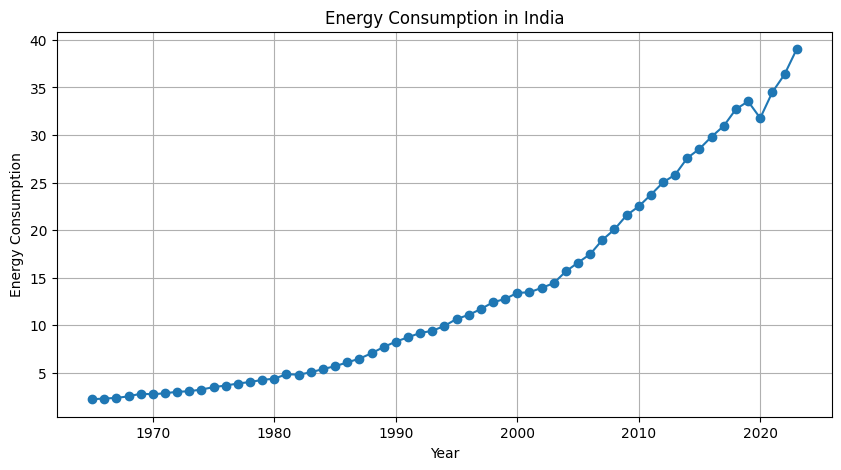

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(data["Year"], data["Energy"], marker="o")

plt.title("Energy Consumption in India")
plt.xlabel("Year")
plt.ylabel("Energy Consumption")
plt.grid(True)
plt.show()

In [ ]:
from sklearn.preprocessing import MinMaxScaler

# Use the first 80% of yearly observations for training
split_index = int(len(data) * 0.8)

scaler = MinMaxScaler(feature_range=(0, 1))

# Fit only on training-period data to prevent leakage
scaler.fit(data[["Energy"]].iloc[:split_index])

scaled_energy = scaler.transform(data[["Energy"]])

print("Original values:")
print(data["Energy"].head())

print("Normalized values:")
print(scaled_energy[:5])

Original values:
0    2.23
1    2.30
2    2.37
3    2.53
4    2.81
Name: Energy, dtype: float64
Normalized values:
[[0.        ]
 [0.00325581]
 [0.00651163]
 [0.01395349]
 [0.02697674]]


In [ ]:
X = []
y = []
target_years = []

for i in range(5, len(scaled_energy)):
    X.append(scaled_energy[i-5:i])
    y.append(scaled_energy[i])
    target_years.append(data["Year"].iloc[i])

X = np.array(X)
y = np.array(y)
target_years = np.array(target_years)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("First 5-year input:", X[0].flatten())
print("First target year:", target_years[0])

X shape: (54, 5, 1)
y shape: (54, 1)
First 5-year input: [0.         0.00325581 0.00651163 0.01395349 0.02697674]
First target year: 1970


In [ ]:
train_mask = target_years < data["Year"].iloc[split_index]

X_train = X[train_mask]
y_train = y[train_mask]

X_test = X[~train_mask]
y_test = y[~train_mask]

years_test = target_years[~train_mask]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Test years:", years_test)

Training samples: 42
Testing samples: 12
Test years: [2012 2013 2014 2015 2016 2017 2018 2019 2020 2021 2022 2023]


In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Input

model = Sequential([
    Input(shape=(5, 1)),
    LSTM(32, activation="tanh"),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,385 (17.13 KB)

 Trainable params: 4,385 (17.13 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=8,
    verbose=1
)

In [ ]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error

# Predict normalized energy values
pred_scaled = model.predict(X_test)

# Convert predictions and targets to original scale
y_actual = scaler.inverse_transform(
    y_test.reshape(-1, 1)
).flatten()

y_predicted = scaler.inverse_transform(
    pred_scaled
).flatten()

# Calculate evaluation metrics
mae = mean_absolute_error(y_actual, y_predicted)

rmse = np.sqrt(
    mean_squared_error(y_actual, y_predicted)
)

print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 296ms/step
MAE: 24.5439
RMSE: 24.785


    Year  Actual  Predicted
0   2012   25.02      5.731
1   2013   25.84      5.937
2   2014   27.59      6.125
3   2015   28.55      6.329
4   2016   29.83      6.524
5   2017   30.96      6.719
6   2018   32.72      6.904
7   2019   33.54      7.116
8   2020   31.78      7.294
9   2021   34.51      7.362
10  2022   36.37      7.499
11  2023   39.02      7.664


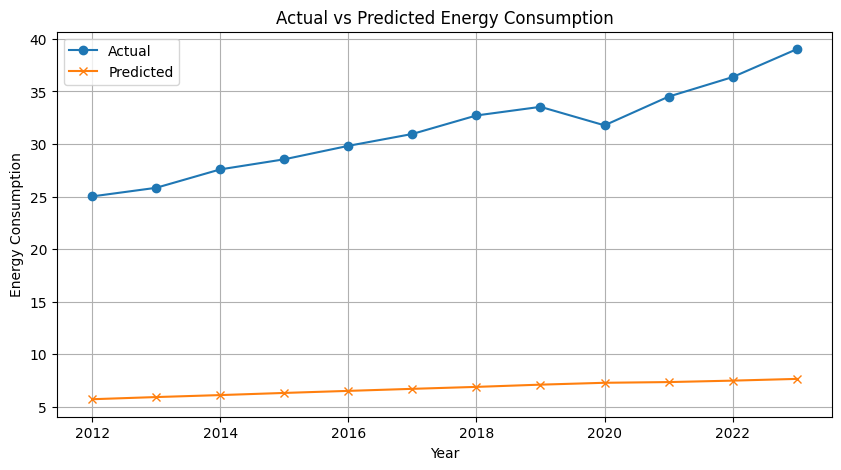

In [ ]:
results = pd.DataFrame({
    "Year": years_test,
    "Actual": y_actual,
    "Predicted": y_predicted
})

print(results.round(3))

plt.figure(figsize=(10, 5))
plt.plot(results["Year"], results["Actual"],
         marker="o", label="Actual")
plt.plot(results["Year"], results["Predicted"],
         marker="x", label="Predicted")

plt.title("Actual vs Predicted Energy Consumption")
plt.xlabel("Year")
plt.ylabel("Energy Consumption")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
last_five_years = scaled_energy[-5:].reshape(1, 5, 1)

next_scaled = model.predict(last_five_years)

next_energy = scaler.inverse_transform(
    next_scaled
)

print("Predicted energy consumption for 2024:",
      round(next_energy[0][0], 3))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 189ms/step
Predicted energy consumption for 2024: 7.867


In [ ]:
# Get country name from user
country = input("Enter country name: ").strip()

# Check whether country exists
if country in df["Country"].astype(str).str.strip().values:
    print("Country found:", country)
else:
    print("Country not found. Please enter a valid country name.")

Enter country name: china
Country not found. Please enter a valid country name.


In [ ]:
country = input("Enter country name: ").strip()

row = df[df["Country"].astype(str).str.strip().str.lower()
         == country.lower()]

if row.empty:
    print("Country not found!")
else:
    years = [c for c in df.columns if str(c).isdigit()]
    energy = pd.to_numeric(row.iloc[0][years], errors="coerce")

    valid_records = energy.dropna()

    if len(valid_records) < 6:
        print("Not enough yearly records!")
    else:
        print("Country:", country)
        print("Available yearly records:", len(valid_records))
        print("You can train the LSTM model for this country.")

Enter country name: Malaysia
Country: Malaysia
Available yearly records: 59
You can train the LSTM model for this country.


In [4]:

# ==========================================
# ENERGYCAST AI - WEBSITE
# Add this as a NEW CELL in your existing Colab
# ==========================================

!pip -q install gradio scikit-learn tensorflow matplotlib

import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gradio as gr
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense

# 1. Use the existing dataset
if "df" not in globals():
    raise ValueError("Run your dataset upload cell first!")

df["Country"] = df["Country"].astype(str).str.strip()

YEAR_COLS = sorted(
    [c for c in df.columns if str(c).strip().isdigit()],
    key=lambda c: int(str(c).strip())
)

if len(YEAR_COLS) < 12:
    raise ValueError("Year columns not detected correctly.")

COUNTRIES = sorted(
    c for c in df["Country"].dropna().unique()
    if c and c.lower() != "nan"
)

LOOKBACK = 5
EPOCHS = 40


# 2. Prepare selected country's data
def prepare_data(country_name):

    country_name = str(country_name or "").strip()

    if not country_name:
        raise gr.Error("Please enter a country name.")

    matches = [
        c for c in COUNTRIES
        if c.lower() == country_name.lower()
    ]

    if not matches:
        suggestions = [
            c for c in COUNTRIES
            if country_name.lower() in c.lower()
        ][:8]

        message = "Country not found."
        if suggestions:
            message += " Suggestions: " + ", ".join(suggestions)

        raise gr.Error(message)

    country = matches[0]

    rows = df[
        df["Country"].str.lower() == country.lower()
    ]

    # Handles duplicate country rows by averaging yearly values
    numeric_rows = rows[YEAR_COLS].apply(
        pd.to_numeric, errors="coerce"
    )

    energy = numeric_rows.mean(axis=0, skipna=True)

    data = pd.DataFrame({
        "Year": [int(str(c)) for c in YEAR_COLS],
        "Energy": energy.to_numpy(dtype=float)
    })

    data = data.sort_values("Year").reset_index(drop=True)

    data["Energy"] = data["Energy"].interpolate(
        limit_direction="both"
    )

    data = data.dropna(subset=["Energy"]).reset_index(drop=True)

    if len(data) < 15:
        raise gr.Error(
            "Not enough yearly records. Choose another country."
        )

    return country, data


# 3. Train model and generate forecast
def generate_forecast(country_name):

    country, data = prepare_data(country_name)

    values = data["Energy"].to_numpy().reshape(-1, 1)

    split = int(len(data) * 0.8)

    if split <= LOOKBACK or split >= len(data):
        raise gr.Error("Not enough data for training and testing.")

    # Fit scaler using training data only
    scaler = MinMaxScaler()
    scaler.fit(values[:split])

    scaled = scaler.transform(values)

    X, y, target_indices = [], [], []

    for i in range(LOOKBACK, len(data)):
        X.append(scaled[i-LOOKBACK:i, 0])
        y.append(scaled[i, 0])
        target_indices.append(i)

    X = np.array(X, dtype=np.float32).reshape(
        -1, LOOKBACK, 1
    )

    y = np.array(y, dtype=np.float32)
    target_indices = np.array(target_indices)

    train_mask = target_indices < split
    test_mask = target_indices >= split

    X_train = X[train_mask]
    y_train = y[train_mask]

    X_test = X[test_mask]
    y_test = y[test_mask]

    test_indices = target_indices[test_mask]

    if len(X_train) == 0 or len(X_test) == 0:
        raise gr.Error("Insufficient training or testing records.")

    # LSTM model
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    model = Sequential([
        Input(shape=(LOOKBACK, 1)),
        LSTM(32, activation="tanh"),
        Dense(16, activation="relu"),
        Dense(1)
    ])

    model.compile(
        optimizer="adam",
        loss="mean_squared_error"
    )

    model.fit(
        X_train,
        y_train,
        epochs=EPOCHS,
        batch_size=min(8, len(X_train)),
        shuffle=False,
        verbose=0
    )

    # 4. Test predictions
    predicted_scaled = model.predict(X_test, verbose=0)

    actual = scaler.inverse_transform(
        y_test.reshape(-1, 1)
    ).flatten()

    predicted = scaler.inverse_transform(
        predicted_scaled
    ).flatten()

    # Simple baseline: use previous year's actual value
    baseline_scaled = scaled[
        test_indices - 1, 0
    ].reshape(-1, 1)

    baseline = scaler.inverse_transform(
        baseline_scaled
    ).flatten()

    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    baseline_mae = mean_absolute_error(actual, baseline)

    baseline_rmse = np.sqrt(
        mean_squared_error(actual, baseline)
    )

    # 5. Forecast next year
    last_five = scaled[-LOOKBACK:].reshape(
        1, LOOKBACK, 1
    )

    next_scaled = model.predict(last_five, verbose=0)

    next_energy = float(
        scaler.inverse_transform(next_scaled)[0, 0]
    )

    last_year = int(data["Year"].iloc[-1])
    next_year = last_year + 1

    # 6. Historical graph
    fig1, ax = plt.subplots(figsize=(10, 4))

    ax.plot(
        data["Year"], data["Energy"],
        marker="o", markersize=3,
        label="Historical consumption"
    )

    ax.set_title(f"Energy Consumption - {country}")
    ax.set_xlabel("Year")
    ax.set_ylabel("Energy consumption (dataset units)")
    ax.grid(True, alpha=0.3)
    ax.legend()
    fig1.tight_layout()

    # 7. Actual vs predicted graph
    test_years = data["Year"].to_numpy()[test_indices]

    fig2, ax = plt.subplots(figsize=(10, 4))

    ax.plot(test_years, actual, marker="o", label="Actual")
    ax.plot(test_years, predicted, marker="x", label="LSTM")
    ax.plot(
        test_years, baseline,
        linestyle="--", label="Previous-year baseline"
    )

    ax.set_title("Actual vs Predicted")
    ax.set_xlabel("Year")
    ax.set_ylabel("Energy consumption (dataset units)")
    ax.grid(True, alpha=0.3)
    ax.legend()
    fig2.tight_layout()

    # 8. Results table and CSV report
    results = pd.DataFrame({
        "Country": country,
        "Year": test_years,
        "Actual": actual,
        "LSTM_Predicted": predicted,
        "Previous_Year_Baseline": baseline,
        "Absolute_Error": np.abs(actual - predicted)
    })

    forecast_row = pd.DataFrame([{
        "Country": country,
        "Year": next_year,
        "Actual": np.nan,
        "LSTM_Predicted": next_energy,
        "Previous_Year_Baseline": float(data["Energy"].iloc[-1]),
        "Absolute_Error": np.nan
    }])

    report = pd.concat(
        [results, forecast_row],
        ignore_index=True
    )

    safe_name = "".join(
        ch if ch.isalnum() or ch in "-_" else "_"
        for ch in country
    )

    report_path = os.path.join(
        tempfile.gettempdir(),
        f"EnergyCast_AI_{safe_name}_report.csv"
    )

    report.to_csv(report_path, index=False)

    summary = f"""
# ⚡ EnergyCast AI — Forecast Results

## Country: {country}

| Prediction | Result |
|---|---:|
| Latest available year | {last_year} |
| Forecast year | **{next_year}** |
| Predicted consumption | **{next_energy:,.4f} dataset units** |

## Model Evaluation

| Metric | LSTM | Previous-year baseline |
|---|---:|---:|
| MAE | {mae:,.4f} | {baseline_mae:,.4f} |
| RMSE | {rmse:,.4f} | {baseline_rmse:,.4f} |

Training sequences: {len(X_train)}

Testing sequences: {len(X_test)}

Input window: Previous {LOOKBACK} years

*Forecasts are estimates, not guarantees. Missing values are interpolated.
Compare the LSTM results with the baseline before interpreting performance.*
"""

    return summary, fig1, fig2, results, report_path


# 9. Website interface
with gr.Blocks(
    theme=gr.themes.Soft(),
    title="EnergyCast AI"
) as app:

    gr.Markdown("""
    # ⚡ EnergyCast AI
    ### World Energy Consumption Forecasting Platform

    Enter a country name to explore historical energy consumption
    and forecast the next year using an LSTM model.
    """)

    with gr.Row():

        country_input = gr.Dropdown(
            choices=COUNTRIES,
            value=(
                "India"
                if any(c.lower() == "india" for c in COUNTRIES)
                else COUNTRIES[0]
            ),
            label="Search country",
            info="Type to filter countries and select a suggestion.",
            allow_custom_value=True,
            interactive=True
        )

        predict_button = gr.Button(
            "Generate Forecast",
            variant="primary"
        )

    summary_output = gr.Markdown()

    with gr.Tabs():

        with gr.Tab("Historical Analytics"):
            history_plot = gr.Plot()

        with gr.Tab("Model Validation"):
            validation_plot = gr.Plot()

        with gr.Tab("Prediction Data"):
            results_table = gr.Dataframe(
                interactive=False
            )

        with gr.Tab("Download Report"):
            download_file = gr.File(
                label="Download CSV report"
            )

    predict_button.click(
        fn=generate_forecast,
        inputs=country_input,
        outputs=[
            summary_output,
            history_plot,
            validation_plot,
            results_table,
            download_file
        ]
    )

print("EnergyCast AI website is starting...")

app.launch(share=True, debug=True)


/tmp/ipykernel_683/2863572269.py:323: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(


EnergyCast AI website is starting...
Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://e6afd1baabcaec18de.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


/tmp/ipykernel_683/2863572269.py:274: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  report = pd.concat(
/tmp/ipykernel_683/2863572269.py:274: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  report = pd.concat(


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://e6afd1baabcaec18de.gradio.live


In [3]:
print("Dataset columns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nDataset shape:")
print(df.shape)

Dataset columns:
['Country', '1965', '1966', '1967', '1968', '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977', '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986', '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995', '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023']

First 5 rows:


,Country,1965,1966,1967,1968,1969,1970,1971,1972,1973,...,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Canada,5.00,5.32,5.57,5.92,6.28,6.73,6.94,7.47,8.11,...,14.43,14.47,14.34,14.54,14.72,14.64,13.76,13.92,14.30,13.95
2,Mexico,1.06,1.12,1.14,1.24,1.36,1.45,1.53,1.69,1.82,...,8.03,7.94,8.11,8.26,8.15,8.07,7.35,7.83,8.18,8.45
3,US,51.98,54.89,56.80,60.19,63.30,65.54,66.92,70.25,73.22,...,93.59,92.69,92.62,92.97,96.37,95.68,88.64,93.44,95.42,94.28
4,Total North America,58.04,61.33,63.51,67.36,70.95,73.72,75.39,79.41,83.16,...,116.04,115.10,115.07,115.76,119.25,118.40,109.75,115.20,117.90,116.68



Dataset shape:
(111, 60)
